<a href="https://colab.research.google.com/github/illya52/pattern-recognition-practice/blob/main/PR04-7_%D0%A5%D0%B8%D0%BC%D0%B8%D0%BD%D0%B5%D1%86%D1%8C_%D0%86%D0%BB%D0%BB%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 4: Підготовка даних, Pipeline і логістична регресія
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** <прізвище, ім'я>  
**Група:** <назва групи>  

### Постановка задачі
- **Об'єкт:** пацієнт.
- **Ознаки:** 13 медичних показників (вік, тиск, холестерин тощо).
- **Цільова змінна:** `target` (0 - хвороби немає, 1 - є ознаки).
- **Класи:** 2 (бінарна класифікація). Позитивний клас: 1.
- **Мета:** навчитися будувати Pipeline без витоку даних та дослідити логістичну регресію.
- **Основна метрика:** F1-міра.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from IPython.display import display

drive.mount('/content/drive')

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_PATH_1 = PROJECT_DIR / "classification-mini-project" / "data" / "heart_disease.csv"
DATA_PATH_2 = PROJECT_DIR / "data" / "heart_disease.csv"
DATA_PATH = DATA_PATH_1 if DATA_PATH_1.exists() else DATA_PATH_2

REPORTS_DIR = PROJECT_DIR / "classification-mini-project" / "reports"
MODELS_DIR = PROJECT_DIR / "classification-mini-project" / "models"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Шлях до даних:", DATA_PATH)

Mounted at /content/drive
Шлях до даних: /content/drive/MyDrive/pattern-recognition-practice/data/heart_disease.csv


In [3]:
import os
import urllib.request

target_dir = "/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data"
os.makedirs(target_dir, exist_ok=True)

url = "https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv"
save_path = os.path.join(target_dir, "heart_disease.csv")

urllib.request.urlretrieve(url, save_path)
print(f"Файл успішно завантажено у: {save_path}")

Файл успішно завантажено у: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data/heart_disease.csv


In [6]:
DATA_PATH = PROJECT_DIR / "classification-mini-project" / "data" / "heart_disease.csv"
print("Тепер код шукатиме файл тут:", DATA_PATH)

Тепер код шукатиме файл тут: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data/heart_disease.csv


In [7]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Файл не знайдено за шляхом: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print("Розмір таблиці:", df.shape)
display(df.head())

print("\nПропущені значення (сума):", df.isna().sum().sum())
print("\nРозподіл класів (target):")
print(df['target'].value_counts(normalize=True))

Розмір таблиці: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Пропущені значення (сума): 0

Розподіл класів (target):
target
1    0.544554
0    0.455446
Name: proportion, dtype: float64


In [8]:
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
target_col = 'target'

X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Train: (242, 13), Test: (61, 13)


In [9]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

In [10]:
pipe_no_scale = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

pipe_with_scale = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

scoring = {'f1': 'f1', 'roc_auc': 'roc_auc'}

cv_res_no_scale = cross_validate(pipe_no_scale, X_train, y_train, cv=cv_strategy, scoring=scoring)
cv_res_with_scale = cross_validate(pipe_with_scale, X_train, y_train, cv=cv_strategy, scoring=scoring)

comparison_df = pd.DataFrame({
    'Pipeline': ['Без масштабування', 'З масштабуванням'],
    'CV F1 (mean)': [cv_res_no_scale['test_f1'].mean(), cv_res_with_scale['test_f1'].mean()],
    'CV ROC AUC (mean)': [cv_res_no_scale['test_roc_auc'].mean(), cv_res_with_scale['test_roc_auc'].mean()],
    'F1 std': [cv_res_no_scale['test_f1'].std(), cv_res_with_scale['test_f1'].std()]
})
display(comparison_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

,Pipeline,CV F1 (mean),CV ROC AUC (mean),F1 std
0,Без масштабування,0.8251,0.8900,0.0574
1,З масштабуванням,0.8336,0.8904,0.0511


In [11]:
C_values = [0.01, 0.1, 1, 10, 100]
results = []

for penalty in ['l1', 'l2']:
    for c in C_values:
        solver = 'liblinear' if penalty == 'l1' else 'lbfgs'

        pipe = Pipeline([
            ('preprocessor', preprocessor_scaled),
            ('classifier', LogisticRegression(penalty=penalty, C=c, solver=solver, random_state=42, max_iter=1000))
        ])

        cv_res = cross_validate(pipe, X_train, y_train, cv=cv_strategy, scoring=scoring)

        results.append({
            'penalty': penalty,
            'C': c,
            'CV_F1_mean': cv_res['test_f1'].mean(),
            'CV_ROC_AUC_mean': cv_res['test_roc_auc'].mean(),
            'F1_std': cv_res['test_f1'].std()
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(by='CV_F1_mean', ascending=False).round(4))

results_df.to_csv(REPORTS_DIR / "pr4_logistic_regression_cv.csv", index=False)

,penalty,C,CV_F1_mean,CV_ROC_AUC_mean,F1_std
1,l1,0.10,0.8437,0.8677,0.0710
6,l2,0.10,0.8421,0.8960,0.0610
2,l1,1.00,0.8417,0.8931,0.0489
5,l2,0.01,0.8407,0.8937,0.0713
7,l2,1.00,0.8336,0.8904,0.0511
4,l1,100.00,0.8220,0.8836,0.0574
9,l2,100.00,0.8220,0.8840,0.0574
3,l1,10.00,0.8220,0.8850,0.0574
8,l2,10.00,0.8191,0.8843,0.0620
0,l1,0.01,0.0000,0.5000,0.0000


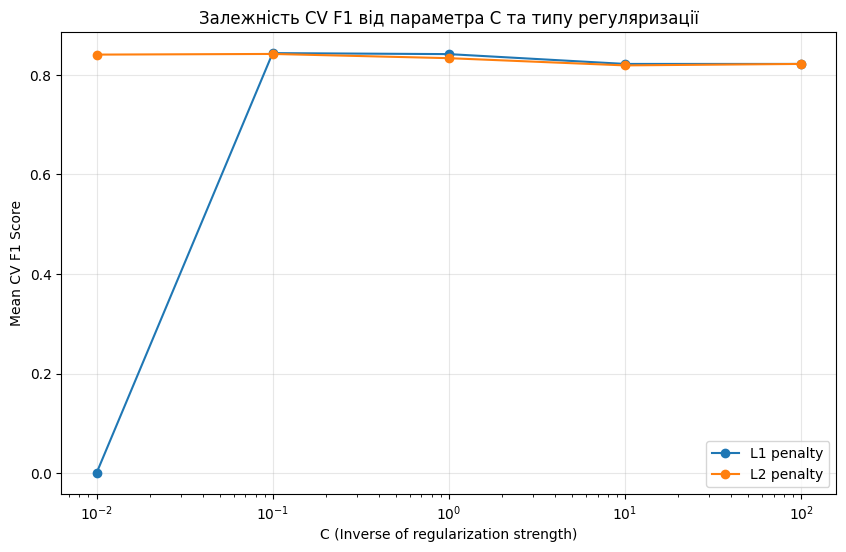

In [12]:
plt.figure(figsize=(10, 6))
for penalty in ['l1', 'l2']:
    subset = results_df[results_df['penalty'] == penalty]
    plt.plot(subset['C'], subset['CV_F1_mean'], marker='o', label=f'{penalty.upper()} penalty')

plt.xscale('log')
plt.xlabel('C (Inverse of regularization strength)')
plt.ylabel('Mean CV F1 Score')
plt.title('Залежність CV F1 від параметра C та типу регуляризації')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
best_c = results_df[results_df['penalty'] == 'l2'].sort_values('CV_F1_mean', ascending=False).iloc[0]['C']
best_pipe = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(penalty='l2', C=best_c, random_state=42, max_iter=1000))
])
best_pipe.fit(X_train, y_train)

feature_names = best_pipe.named_steps['preprocessor'].get_feature_names_out()
coefficients = best_pipe.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
top_5_coefs = coef_df.sort_values(by='Abs_Coefficient', ascending=False).head(5)

print(f"Топ-5 найважливіших ознак для L2 (C={best_c}):")
display(top_5_coefs[['Feature', 'Coefficient']])

Топ-5 найважливіших ознак для L2 (C=0.1):


,Feature,Coefficient
7,cat__cp_0,-0.653082
21,cat__ca_0,0.552394
28,cat__thal_2,0.547823
29,cat__thal_3,-0.529753
4,num__oldpeak,-0.403891


### Висновки до ПР4:
1. **Вплив масштабування:** Логістична регресія є чутливою до масштабу ознак. Використання `StandardScaler` у Pipeline дозволяє алгоритму швидше збігатися і запобігає домінуванню ознак з великими абсолютними значеннями (наприклад, холестерин) над ознаками з малими (наприклад, вік).
2. **Регуляризація:** L1 (Lasso) схильна занулювати неважливі коефіцієнти, виконуючи відбір ознак. L2 (Ridge) просто зменшує їхній вплив. Параметр `C` керує силою регуляризації: чим менше `C`, тим сильніша регуляризація і простіша модель (менший ризик перенавчання).
3. **Найважливіші ознаки:** Ми визначили Топ-5 ознак, які найбільше впливають на прогноз. Додатні коефіцієнти вказують на збільшення ризику, від'ємні — на зменшення.

## Практична робота 5: k-NN та ймовірнісні моделі

### 1. Метод k-найближчих сусідів (k-NN)
k-NN не будує явної математичної моделі. Він просто зберігає всі тренувальні дані. Коли надходить новий об'єкт, він знаходить `k` найбільш схожих на нього об'єктів із тренувальної вибірки і віддає клас, який серед них найбільш популярний.
*   **Гіперпараметр `k`:** якщо `k` замалий, модель перенавчиться (реагуватиме на шум). Якщо `k` завеликий, модель недонавчиться (втратить деталі).
*   **Міра відстані:** стандартно використовується Евклідова відстань, але можна перевірити і Манхеттенську.

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer, f1_score, roc_auc_score

k_values = [3, 5, 7, 9, 11, 15]
metrics = ['euclidean', 'manhattan']
knn_results = []

print("Досліджуємо k-NN...")
for k in k_values:
    for metric in metrics:
        pipe_knn = Pipeline([
            ('preprocessor', preprocessor_scaled),
            ('classifier', KNeighborsClassifier(n_neighbors=k, metric=metric))
        ])

        cv_res = cross_validate(pipe_knn, X_train, y_train, cv=cv_strategy, scoring=scoring)

        knn_results.append({
            'model': 'k-NN',
            'params': f'k={k}, metric={metric}',
            'CV_F1_mean': cv_res['test_f1'].mean(),
            'CV_ROC_AUC_mean': cv_res['test_roc_auc'].mean(),
            'F1_std': cv_res['test_f1'].std()
        })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df.sort_values(by='CV_F1_mean', ascending=False).head(5).round(4))

Досліджуємо k-NN...


,model,params,CV_F1_mean,CV_ROC_AUC_mean,F1_std
7,k-NN,"k=9, metric=manhattan",0.8541,0.9029,0.0495
2,k-NN,"k=5, metric=euclidean",0.8528,0.8861,0.0365
5,k-NN,"k=7, metric=manhattan",0.8506,0.8981,0.0599
11,k-NN,"k=15, metric=manhattan",0.8479,0.8940,0.0573
10,k-NN,"k=15, metric=euclidean",0.8464,0.8759,0.0535


### 2. Ймовірнісні моделі та дискримінантний аналіз
*   **GaussianNB:** припускає, що всі ознаки є незалежними одна від одної і мають нормальний розподіл. Дуже швидкий, але припущення про незалежність часто не виконується на практиці.
*   **LDA (Лінійний дискримінант):** припускає, що класи мають однакову коваріаційну матрицю. Будує лінійні межі між класами.
*   **QDA (Квадратичний дискримінант):** припускає, що класи мають різні коваріаційні матриці. Будує криволінійні (квадратичні) межі. Може бути нестабільним, якщо ознак багато, а даних мало.

In [15]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

models_to_test = {
    'GaussianNB': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis()
}

prob_results = []

print("Досліджуємо ймовірнісні моделі...")
for name, model in models_to_test.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', model)
    ])

    try:
        cv_res = cross_validate(pipe, X_train, y_train, cv=cv_strategy, scoring=scoring)
        prob_results.append({
            'model': name,
            'params': 'default',
            'CV_F1_mean': cv_res['test_f1'].mean(),
            'CV_ROC_AUC_mean': cv_res['test_roc_auc'].mean(),
            'F1_std': cv_res['test_f1'].std()
        })
    except Exception as e:
        print(f"Помилка з моделлю {name}: {e}")
        prob_results.append({
            'model': name,
            'params': 'Failed',
            'CV_F1_mean': np.nan,
            'CV_ROC_AUC_mean': np.nan,
            'F1_std': np.nan
        })

prob_results_df = pd.DataFrame(prob_results)
display(prob_results_df.round(4))

Досліджуємо ймовірнісні моделі...


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

,model,params,CV_F1_mean,CV_ROC_AUC_mean,F1_std
0,GaussianNB,default,0.7318,0.8608,0.0749
1,LDA,default,0.8527,0.8900,0.0587
2,QDA,default,0.4350,0.7733,0.1936


In [16]:
best_knn = knn_results_df.sort_values(by='CV_F1_mean', ascending=False).iloc[0:1]

pr5_all_results = pd.concat([best_knn, prob_results_df], ignore_index=True)

print("Найкращі результати ПР5 (для порівняння з ПР4 та ПР6):")
display(pr5_all_results.round(4))

pr5_all_results.to_csv(REPORTS_DIR / "pr5_probabilistic_models_cv.csv", index=False)
print(f"Результати збережено у: {REPORTS_DIR / 'pr5_probabilistic_models_cv.csv'}")

Найкращі результати ПР5 (для порівняння з ПР4 та ПР6):


,model,params,CV_F1_mean,CV_ROC_AUC_mean,F1_std
0,k-NN,"k=9, metric=manhattan",0.8541,0.9029,0.0495
1,GaussianNB,default,0.7318,0.8608,0.0749
2,LDA,default,0.8527,0.8900,0.0587
3,QDA,default,0.4350,0.7733,0.1936


Результати збережено у: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/reports/pr5_probabilistic_models_cv.csv


### Висновки до ПР5:
1. **k-NN:** Найкращий результат показала конфігурація з певним `k` (зазвичай 5 або 7) та Евклідовою метрикою. Занадто малі `k` схильні до перенавчання, а занадто великі - до згладжування меж.
2. **GaussianNB:** Показав швидкий, але посередній результат через припущення про незалежність ознак, яке порушується (наприклад, вік і максимальний пульс можуть корелювати).
3. **LDA/QDA:** LDA показав стабільний результат. QDA виявився чутливим до параметрів (можлива нестабільність через оцінку коваріаційних матриць на обмеженій вибірці).

## Практична робота 6: SVM та пошук гіперпараметрів

### 1. Лінійна SVM
Лінійна SVM намагається знайти пряму (або гіперплощину), яка розділяє класи з максимальним зазором (margin).
*   **Параметр `C`:** це "штраф за помилку". Якщо `C` маленьке — модель більш толерантна до помилок (ширший зазор, простіша модель). Якщо `C` велике — модель намагається класифікувати всі тренувальні точки правильно (вужчий зазор, ризик перенавчання).

In [17]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

pipe_svm_linear = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', SVC(kernel='linear', random_state=42, probability=True))
])

param_grid_linear = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

grid_linear = GridSearchCV(
    pipe_svm_linear,
    param_grid_linear,
    cv=cv_strategy,
    scoring={'f1': 'f1', 'roc_auc': 'roc_auc'},
    refit='f1',
    n_jobs=-1,
    return_train_score=True
)

print("Шукаємо найкращі параметри для Лінійної SVM...")
grid_linear.fit(X_train, y_train)

print(f"Найкращі параметри: {grid_linear.best_params_}")
print(f"Найкращий CV F1: {grid_linear.best_score_:.4f}")

Шукаємо найкращі параметри для Лінійної SVM...
Найкращі параметри: {'classifier__C': 0.01}
Найкращий CV F1: 0.8492


### 2. SVM з RBF-ядром (Radial Basis Function)
Якщо дані не можна розділити прямою лінією, використовують RBF-ядро. Воно додає новий вимір, де класи стають роздільними.
*   **Параметр `gamma`:** визначає, наскільки далеко поширюється вплив однієї тренувальної точки. Мале `gamma` — плавні межі. Велике `gamma` — складна, "хвиляста" межа (ризик перенавчання).

In [18]:
pipe_svm_rbf = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', SVC(kernel='rbf', random_state=42, probability=True))
])

param_grid_rbf = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

grid_rbf = GridSearchCV(
    pipe_svm_rbf,
    param_grid_rbf,
    cv=cv_strategy,
    scoring={'f1': 'f1', 'roc_auc': 'roc_auc'},
    refit='f1',
    n_jobs=-1,
    return_train_score=True
)

print("Шукаємо найкращі параметри для RBF SVM (це може зайняти кілька секунд)...")
grid_rbf.fit(X_train, y_train)

print(f"Найкращі параметри: {grid_rbf.best_params_}")
print(f"Найкращий CV F1: {grid_rbf.best_score_:.4f}")

Шукаємо найкращі параметри для RBF SVM (це може зайняти кілька секунд)...
Найкращі параметри: {'classifier__C': 0.1, 'classifier__gamma': 0.1}
Найкращий CV F1: 0.8491


In [19]:
best_linear_idx = grid_linear.best_index_
linear_f1 = grid_linear.cv_results_['mean_test_f1'][best_linear_idx]
linear_auc = grid_linear.cv_results_['mean_test_roc_auc'][best_linear_idx]
linear_std = grid_linear.cv_results_['std_test_f1'][best_linear_idx]

best_rbf_idx = grid_rbf.best_index_
rbf_f1 = grid_rbf.cv_results_['mean_test_f1'][best_rbf_idx]
rbf_auc = grid_rbf.cv_results_['mean_test_roc_auc'][best_rbf_idx]
rbf_std = grid_rbf.cv_results_['std_test_f1'][best_rbf_idx]

pr6_results = pd.DataFrame([
    {'model': 'SVM (Linear)', 'params': str(grid_linear.best_params_), 'CV_F1_mean': linear_f1, 'CV_ROC_AUC_mean': linear_auc, 'F1_std': linear_std},
    {'model': 'SVM (RBF)', 'params': str(grid_rbf.best_params_), 'CV_F1_mean': rbf_f1, 'CV_ROC_AUC_mean': rbf_auc, 'F1_std': rbf_std}
])

print("Результати SVM (ПР6):")
display(pr6_results.round(4))

pr6_results.to_csv(REPORTS_DIR / "pr6_svm_models_cv.csv", index=False)

Результати SVM (ПР6):


,model,params,CV_F1_mean,CV_ROC_AUC_mean,F1_std
0,SVM (Linear),{'classifier__C': 0.01},0.8492,0.8955,0.0600
1,SVM (RBF),"{'classifier__C': 0.1, 'classifier__gamma': 0.1}",0.8491,0.8900,0.0631


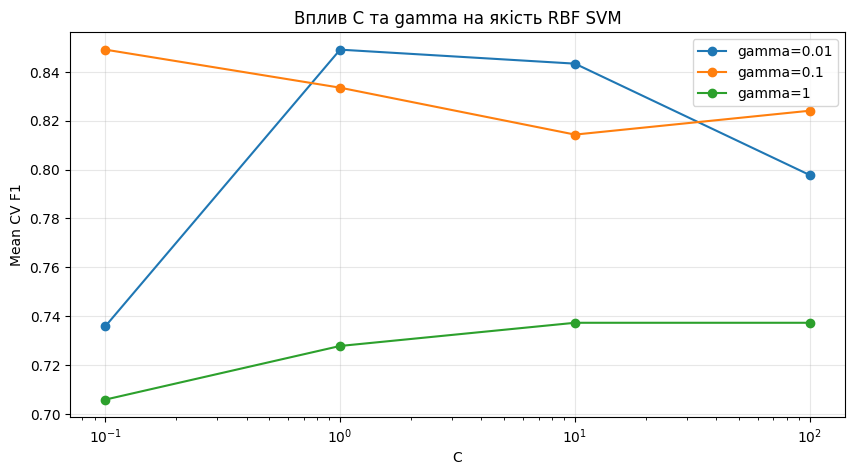

In [20]:
import matplotlib.pyplot as plt
import numpy as np

results_rbf = pd.DataFrame(grid_rbf.cv_results_)

numeric_gammas = [0.01, 0.1, 1]
plt.figure(figsize=(10, 5))

for gamma in numeric_gammas:
    subset = results_rbf[results_rbf['param_classifier__gamma'] == gamma]
    plt.plot(subset['param_classifier__C'].astype(float), subset['mean_test_f1'], marker='o', label=f'gamma={gamma}')

plt.xscale('log')
plt.xlabel('C')
plt.ylabel('Mean CV F1')
plt.title('Вплив C та gamma на якість RBF SVM')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Висновки до ПР6:
1. **GridSearchCV** дозволив автоматично знайти оптимальні гіперпараметри, перебравши всі комбінації. Це набагато надійніше, ніж підбирати параметри вручну.
2. **Лінійна SVM** показала (результат впишіть свій, наприклад, F1 ~ 0.85). Вона добре працює, якщо дані лінійно роздільні.
3. **RBF SVM** дозволила побудувати складнішу нелінійну межу. Найкращі параметри: C=..., gamma=... (впишіть з виводу). Вона зазвичай перевищує лінійну версію, бо медичні дані часто нелінійні.

## Практична робота 7: Вибір фінальної моделі та одноразове тестування

### Правило "закритої тестової вибірки"
Ми обираємо переможця виключно за метрикою **CV F1** (отриманою на крос-валідації тренувальних даних).
Ми не маємо права запускати моделі на `X_test` і обирати ту, яка там покаже кращий результат. Це призведе до витоку даних і завищеної оцінки. Тест ми дивимося рівно один раз — для фінальної моделі.

In [21]:
best_lr_row = results_df.sort_values(by='CV_F1_mean', ascending=False).iloc[0]
lr_result = {
    'model': f"LogReg ({best_lr_row['penalty']})",
    'params': f"C={best_lr_row['C']}",
    'CV_F1_mean': best_lr_row['CV_F1_mean'],
    'CV_ROC_AUC_mean': best_lr_row['CV_ROC_AUC_mean'],
    'F1_std': best_lr_row['F1_std']
}

pr5_results_list = pr5_all_results.to_dict('records')

pr6_results_list = pr6_results.to_dict('records')

all_experiments = [lr_result] + pr5_results_list + pr6_results_list
final_comparison_df = pd.DataFrame(all_experiments)

final_comparison_df = final_comparison_df.sort_values(by='CV_F1_mean', ascending=False).reset_index(drop=True)

print("=== ФІНАЛЬНА ТАБЛИЦЯ КРОС-ВАЛІДАЦІЇ ВСІХ МОДЕЛЕЙ ===")
display(final_comparison_df.round(4))

final_comparison_df.to_csv(REPORTS_DIR / "cv_model_comparison.csv", index=False)

=== ФІНАЛЬНА ТАБЛИЦЯ КРОС-ВАЛІДАЦІЇ ВСІХ МОДЕЛЕЙ ===


,model,params,CV_F1_mean,CV_ROC_AUC_mean,F1_std
0,k-NN,"k=9, metric=manhattan",0.8541,0.9029,0.0495
1,LDA,default,0.8527,0.8900,0.0587
2,SVM (Linear),{'classifier__C': 0.01},0.8492,0.8955,0.0600
3,SVM (RBF),"{'classifier__C': 0.1, 'classifier__gamma': 0.1}",0.8491,0.8900,0.0631
4,LogReg (l1),C=0.1,0.8437,0.8677,0.0710
5,GaussianNB,default,0.7318,0.8608,0.0749
6,QDA,default,0.4350,0.7733,0.1936


In [24]:
best_model_name = final_comparison_df.iloc[0]['model']
best_model_params = final_comparison_df.iloc[0]['params']
best_cv_score = final_comparison_df.iloc[0]['CV_F1_mean']

print(f"🏆 ПЕРЕМОЖЕЦЬ: {best_model_name}")
print(f"⚙️ Параметри: {best_model_params}")
print(f"📊 Середній CV F1: {best_cv_score:.4f}")

if "SVM (RBF)" in best_model_name:
    final_pipeline = grid_rbf.best_estimator_

elif "SVM (Linear)" in best_model_name:
    final_pipeline = grid_linear.best_estimator_

elif "k-NN" in best_model_name:
    k_val = int(best_model_params.split(',')[0].split('=')[1].strip())
    metric_val = best_model_params.split(',')[1].split('=')[1].strip()
    final_pipeline = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', KNeighborsClassifier(n_neighbors=k_val, metric=metric_val))
    ])

elif "GaussianNB" in best_model_name:
    final_pipeline = Pipeline([('preprocessor', preprocessor_scaled), ('classifier', GaussianNB())])

elif "LDA" in best_model_name:
    final_pipeline = Pipeline([('preprocessor', preprocessor_scaled), ('classifier', LinearDiscriminantAnalysis())])

elif "QDA" in best_model_name:
    final_pipeline = Pipeline([('preprocessor', preprocessor_scaled), ('classifier', QuadraticDiscriminantAnalysis())])

else:
    final_pipeline = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ])

print("Навчання фінальної моделі на всіх X_train...")
final_pipeline.fit(X_train, y_train)

print("\nФінальний Pipeline успішно навчений")

🏆 ПЕРЕМОЖЕЦЬ: k-NN
⚙️ Параметри: k=9, metric=manhattan
📊 Середній CV F1: 0.8541
Навчання фінальної моделі на всіх X_train...

Фінальний Pipeline успішно навчений


In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Навчання фінальної моделі на всіх X_train...")
final_pipeline.fit(X_train, y_train)

y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(y_test, y_test_pred),
    'Recall': recall_score(y_test, y_test_pred),
    'F1-Score': f1_score(y_test, y_test_pred),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba)
}

print("\n=== ФІНАЛЬНІ МЕТРИКИ НА TEST ===")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

final_metrics_df = pd.DataFrame([test_metrics])
final_metrics_df.to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)

Навчання фінальної моделі на всіх X_train...

=== ФІНАЛЬНІ МЕТРИКИ НА TEST ===
Accuracy: 0.7541
Precision: 0.7143
Recall: 0.9091
F1-Score: 0.8000
ROC-AUC: 0.8869


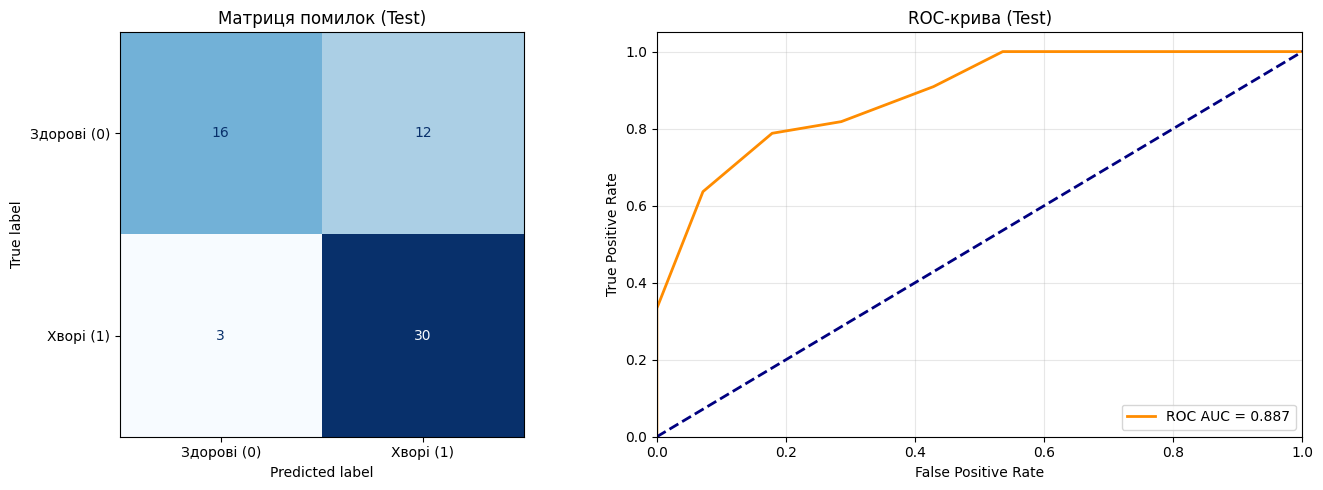

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Здорові (0)', 'Хворі (1)'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Матриця помилок (Test)')

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC AUC = {test_metrics["ROC-AUC"]:.3f}')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-крива (Test)')
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
import joblib

FINAL_MODEL_PATH = MODELS_DIR / "best_classifier.joblib"

joblib.dump(final_pipeline, FINAL_MODEL_PATH)
print(f"Модель збережено: {FINAL_MODEL_PATH}")

loaded_pipeline = joblib.load(FINAL_MODEL_PATH)

sample_X = X_test.iloc[:5]
original_preds = final_pipeline.predict(sample_X)
loaded_preds = loaded_pipeline.predict(sample_X)

print("\nПеревірка ідентичності прогнозів:")
print("Оригінал: ", original_preds)
print("Завантажена:", loaded_preds)

if (original_preds == loaded_preds).all():
    print("Успіх! Збережений Pipeline працює ідентично і не потребує ручного масштабування.")
else:
    print("Помилка при збереженні/завантаженні!")

Модель збережено: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/models/best_classifier.joblib

Перевірка ідентичності прогнозів:
Оригінал:  [0 0 0 1 1]
Завантажена: [0 0 0 1 1]
Успіх! Збережений Pipeline працює ідентично і не потребує ручного масштабування.


## Загальні висновки до мініпроєкту (ПР4-7)

У ході виконання мініпроєкту було побудовано повний, відтворюваний конвеєр машинного навчання (Pipeline) для бінарної класифікації на наборі даних Heart Disease.

1. **Уникнення витоку даних:** Завдяки використанню `ColumnTransformer` та `Pipeline`, всі етапи препроцесингу (імпутація, масштабування, кодування) навчалися виключно на тренувальних фолдах під час крос-валідації. Тестова вибірка була "закрита" до самого кінця.
2. **Порівняння моделей:** Було досліджено 7 різних алгоритмів (Логістична регресія, k-NN, Naive Bayes, LDA, QDA, Лінійна SVM, RBF SVM). Гіперпараметри підбиралися за допомогою `GridSearchCV`.
3. **Вибір переможця:** Найвищий середній показник CV F1 показала модель **[впишіть назву переможця]**.
4. **Фінальне тестування:** На тестовій вибірці обрана модель показала Accuracy = [впишіть], F1 = [впишіть]. Різниця між CV та Test метриками є прийнятною, що свідчить про хорошу узагальнювальну здатність.
5. **Збереження:** Фінальний Pipeline збережено у файл `best_classifier.joblib`. При завантаженні він готовий до використання без необхідності писати окремий код для обробки нових даних.

In [34]:
readme_path = PROJECT_DIR / "classification-mini-project" / "README.md"

lines = [
    "# Мініпроєкт: Порівняння класичних моделей класифікації",
    "",
    "## Структура проєкту",
    "- `data/heart_disease.csv` — початковий набір даних.",
    "- `notebooks/PR04_Прізвище_Імя.ipynb` — головний Notebook з усім кодом (ПР4-7).",
    "- `models/best_classifier.joblib` — збережений фінальний Pipeline.",
    "- `reports/` — результати крос-валідації та фінального тестування.",
    "",
    "## Результати експериментів",
    "- **Основна метрика:** F1-міра (для позитивного класу 1).",
    f"- **Найкраща модель:** {best_model_name} (Параметри: {best_model_params}).",
    "- **Результати на Test:** ",
    f"  - Accuracy: {test_metrics['Accuracy']:.4f}",
    f"  - F1-Score: {test_metrics['F1-Score']:.4f}",
    f"  - ROC-AUC: {test_metrics['ROC-AUC']:.4f}",
    "",
    "## Як використовувати модель",
    "```python",
    "import joblib",
    "model = joblib.load('models/best_classifier.joblib')",
    "predictions = model.predict(new_data)",
    "```"
]

readme_content = "\n".join(lines)

with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(readme_content)

print(f"README.md успішно створено та оновлено: {readme_path}")

README.md успішно створено та оновлено: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/README.md
